In [1]:
# Importing Libraries
import ast
import pandas as pd
from datasets import load_dataset
import matplotlib.pyplot as plt 

# Loading Data
dataset = load_dataset('lukebarousse/data_jobs')
df = dataset['train'].to_pandas()

# Data Cleanup
df['job_posted_date'] = pd.to_datetime(df['job_posted_date'])
df['job_skills'] = df['job_skills'].apply(lambda x: ast.literal_eval(x) if pd.notna(x) else x)

In [2]:
df

,job_title_short,job_title,job_location,job_via,job_schedule_type,job_work_from_home,search_location,job_posted_date,job_no_degree_mention,job_health_insurance,job_country,salary_rate,salary_year_avg,salary_hour_avg,company_name,job_skills,job_type_skills
0,Senior Data Engineer,Senior Clinical Data Engineer / Principal Clin...,"Watertown, CT",via Work Nearby,Full-time,False,"Texas, United States",2023-06-16 13:44:15,False,False,United States,NaN,NaN,NaN,Boehringer Ingelheim,NaN,NaN
1,Data Analyst,Data Analyst,"Guadalajara, Jalisco, Mexico",via BeBee México,Full-time,False,Mexico,2023-01-14 13:18:07,False,False,Mexico,NaN,NaN,NaN,Hewlett Packard Enterprise,"[r, python, sql, nosql, power bi, tableau]","{'analyst_tools': ['power bi', 'tableau'], 'pr..."
2,Data Engineer,"Data Engineer/Scientist/Analyst, Mid or Senior...","Berlin, Germany",via LinkedIn,Full-time,False,Germany,2023-10-10 13:14:55,False,False,Germany,NaN,NaN,NaN,ALPHA Augmented Services,"[python, sql, c#, azure, airflow, dax, docker,...","{'analyst_tools': ['dax'], 'cloud': ['azure'],..."
3,Data Engineer,LEAD ENGINEER - PRINCIPAL ANALYST - PRINCIPAL ...,"San Antonio, TX",via Diversity.com,Full-time,False,"Texas, United States",2023-07-04 13:01:41,True,False,United States,NaN,NaN,NaN,Southwest Research Institute,"[python, c++, java, matlab, aws, tensorflow, k...","{'cloud': ['aws'], 'libraries': ['tensorflow',..."
4,Data Engineer,Data Engineer- Sr Jobs,"Washington, DC",via Clearance Jobs,Full-time,False,Sudan,2023-08-07 14:29:36,False,False,Sudan,NaN,NaN,NaN,Kristina Daniel,"[bash, python, oracle, aws, ansible, puppet, j...","{'cloud': ['oracle', 'aws'], 'other': ['ansibl..."
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
785736,Software Engineer,DevOps Engineer,Singapura,melalui Trabajo.org,Pekerjaan tetap,False,Singapore,2023-03-13 06:16:16,False,False,Singapore,NaN,NaN,NaN,CAREERSTAR INTERNATIONAL PTE. LTD.,"[bash, python, perl, linux, unix, kubernetes, ...","{'os': ['linux', 'unix'], 'other': ['kubernete..."
785737,Data Analyst,CRM Data Analyst,"Bad Rodach, Jerman",melalui BeBee Deutschland,Pekerjaan tetap,False,Germany,2023-03-12 06:18:18,False,False,Germany,NaN,NaN,NaN,HABA FAMILYGROUP,"[sas, sas, sql, excel]","{'analyst_tools': ['sas', 'excel'], 'programmi..."
785738,Business Analyst,Commercial Analyst - Start Now,Malaysia,melalui Ricebowl,Pekerjaan tetap,False,Malaysia,2023-03-12 06:32:36,False,False,Malaysia,NaN,NaN,NaN,Lendlease Corporation,"[powerpoint, excel]","{'analyst_tools': ['powerpoint', 'excel']}"
785739,Data Engineer,"Principal Associate, Data Engineer (Remote-Eli...","Newark, New Jersey, Amerika Serikat",melalui Recruit.net,Pekerjaan tetap,False,Sudan,2023-03-12 06:32:15,False,False,Sudan,NaN,NaN,NaN,Capital One,"[python, go, nosql, sql, mongo, shell, mysql, ...","{'cloud': ['aws', 'snowflake', 'azure', 'redsh..."


### Problem #1 Statement:
Create a scatter plot to compare the median yearly salary and the number of jobs based on the job_title_short column.
To create the scatter plot first create a new DataFrame using the groupby() method to aggregate and find the median salary and job count for each job title.
Annotate each point with the job title name.

In [3]:
job_title_stats = df.groupby("job_title_short").agg(
    job_count = ("job_title_short", "count"), # column name = (column we want to do operation with, what to do with it)
    median_salary_year_avg = ("salary_year_avg", "median")

).dropna()

job_title_stats

# 1. job_title_stats =
# Creates a new DataFrame variable to store the resulting aggregated data without modifying the original DataFrame df.

# 2. df.groupby("job_title_short")
# Splits the DataFrame into groups based on each unique job title (e.g., Data Analyst, Data Scientist, Data Engineer). All subsequent calculations will be performed independently on each of these groups.

# 3. .agg(...)
# Short for aggregate. This method allows you to apply calculation functions (like count, mean, median) to specified columns within each group.

# 4. job_count = ("job_title_short", "count")
# Uses Pandas named aggregation with the tuple syntax ("column_to_target", "function_to_apply"):

# job_count: The name given to the new column in the output DataFrame.

# "job_title_short": The column being counted.

# "count": Counts the number of non-null entries in that group to get total job postings for that job title.

# 5. median_salary = ("salary_year_avg", "median")
# median_salary: The name given to the second output column.

# "salary_year_avg": The column containing yearly salary data.

# "median": Calculates the 50th percentile (median) salary for each job title.

# 6. .dropna()
# Removes any row from the resulting DataFrame that contains NaN (missing) values. If a job title has no salary entries, its median_salary will be NaN; .dropna() filters those out so they don't break the scatter plot.

,job_count,median_salary_year_avg
job_title_short,,
Business Analyst,49063,85000.0
Cloud Engineer,12331,90000.0
Data Analyst,196075,90000.0
Data Engineer,186241,125000.0
Data Scientist,172286,127500.0
Machine Learning Engineer,14080,106415.0
Senior Data Analyst,29216,111175.0
Senior Data Engineer,44563,147500.0
Senior Data Scientist,36957,155500.0


Text(0.5, 1.0, 'Median Yearly Salary vs Count of Job Postings')

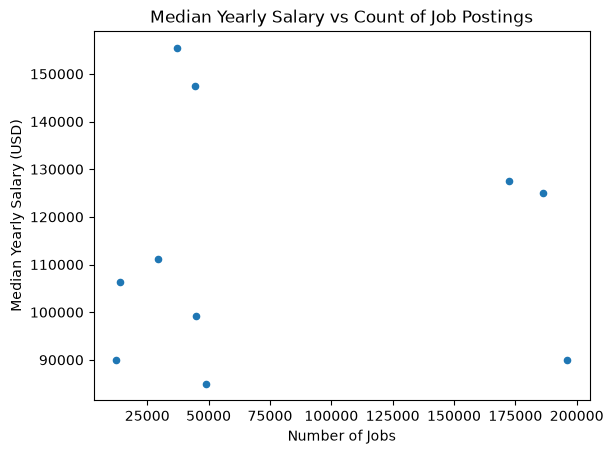

In [4]:
job_title_stats = df.groupby("job_title_short").agg(
    job_count = ("job_title_short", "count"),
    median_salary_year_avg = ("salary_year_avg", "median")

).dropna()

job_title_stats.plot(kind='scatter', x='job_count', y='median_salary_year_avg')
plt.xlabel('Number of Jobs')
plt.ylabel('Median Yearly Salary (USD)')
plt.title('Median Yearly Salary vs Count of Job Postings')

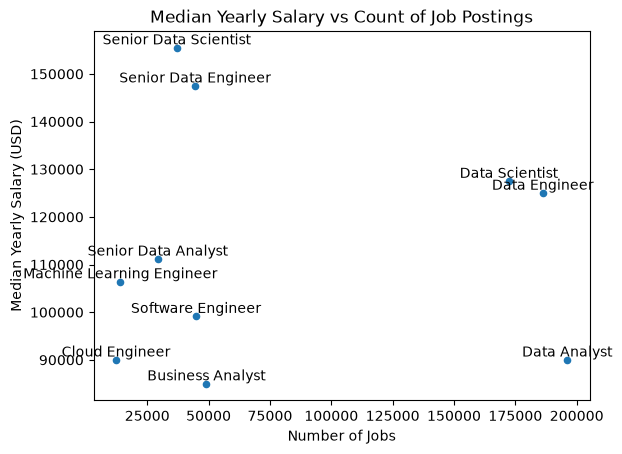

In [5]:
job_title_stats = df.groupby("job_title_short").agg(
    job_count = ("job_title_short", "count"),
    median_salary_year_avg = ("salary_year_avg", "median")

).dropna()

job_title_stats.plot(kind='scatter', x='job_count', y='median_salary_year_avg')
plt.xlabel('Number of Jobs')
plt.ylabel('Median Yearly Salary (USD)')
plt.title('Median Yearly Salary vs Count of Job Postings')

for i in range(len(job_title_stats)):
   job_count = job_title_stats['job_count'].iloc[i]
   mean_salary = job_title_stats['median_salary_year_avg'].iloc[i]
   job_title = job_title_stats.index[i]
   plt.text(job_count, mean_salary, job_title, ha='center', va='bottom')

plt.show()


# 1. for i in range(len(job_title_stats)):
# - len(job_title_stats): Calculates the total number of rows (data points) in your DataFrame.

# - range(...): Generates a sequence of integers from 0 up to N - 1 (where N is the number of rows).

# - for i in ...: Iterates through each row position index i one by one so you can process every scatter plot point sequentially.

# 2. job_count = job_title_stats['job_count'].iloc[i]
# - ['job_count']: Selects the job_count column.

# - .iloc[i]: Extracts the value at row position i using integer-based indexing.

# - job_count =: Stores this numerical value, which acts as the x-coordinate for the point on the plot.

# 3. mean_salary = job_title_stats['median_salary_year_avg'].iloc[i]
# - ['median_salary_year_avg']: Selects the median salary column.

# -.iloc[i]: Extracts the salary value at row position i.

# - mean_salary =: Stores this numerical value, which acts as the y-coordinate for the point on the plot (Note: even though the variable is named mean_salary, it contains the median salary value from your aggregation).

# 4. job_title = job_title_stats.index[i]
# - job_title_stats.index: Accesses the DataFrame's index, which contains the unique job titles (because groupby("job_title_short") sets the grouped column as the index).

# - [i]: Gets the job title text label (e.g., "Data Analyst") at row i.

# 5. plt.text(job_count, mean_salary, job_title, ha='center', va='bottom')
# - Places the text label on the plot canvas at the specified location:

# - job_count: The x-position where the text will be placed.

# - mean_salary: The y-position where the text will be placed.

# - job_title: The string text to display on the chart.

# - ha='center': Horizontal Alignment — centers the text horizontally over the point's dot.

# - va='bottom': Vertical Alignment — anchors the bottom of the text to the coordinates, making the text sit directly above the dot rather than overlapping it.

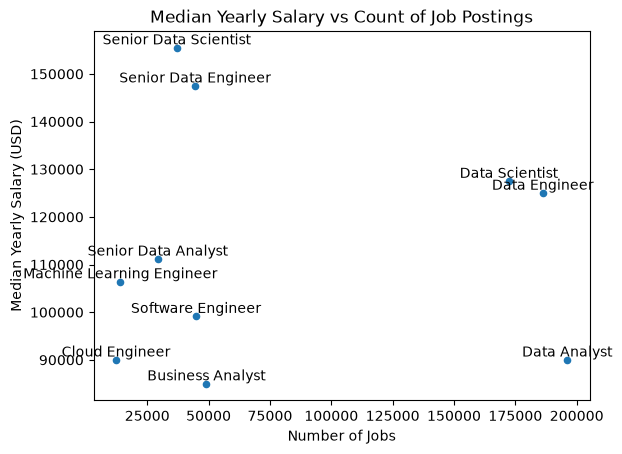

In [6]:
# method like in theory lesson
job_title_stats = df.groupby("job_title_short").agg(
    job_count = ("job_title_short", "count"),
    median_salary_year_avg = ("salary_year_avg", "median")

).dropna()

job_title_stats.plot(kind='scatter', x='job_count', y='median_salary_year_avg')
plt.xlabel('Number of Jobs')
plt.ylabel('Median Yearly Salary (USD)')
plt.title('Median Yearly Salary vs Count of Job Postings')

for i, txt in enumerate(job_title_stats.index):
   plt.text(job_title_stats['job_count'].iloc[i], job_title_stats['median_salary_year_avg'].iloc[i], job_title_stats.index[i], ha='center', va='bottom') # index of job_title_stats is job_title_short

plt.show()

### Problem #2 Statement:
Create a scatter plot to visualize the relationship between the number of job postings and median yearly salary for the top 7 countries based on highest number of job postings. Annotate each point with the country's name.

In [7]:
df.groupby("job_country").agg( # df has all columns we are calling - salary_year_avg and job_country
    median_salary_year_avg = ("salary_year_avg", "median"),
    job_count = ("job_country", "count")
).dropna() # dropna so that we dont consider NaN values

,median_salary_year_avg,job_count
job_country,,
Albania,69962.5,119
Algeria,44550.0,111
Argentina,96773.0,8736
Armenia,76500.0,289
Australia,119250.0,12955
...,...,...
Uruguay,57500.0,1386
Uzbekistan,30750.0,333
Vietnam,79200.0,2414


In [8]:
country_stats = df.groupby("job_country").agg( 
    median_salary_year_avg = ("salary_year_avg", "median"),
    job_count = ("job_country", "count")
).dropna()

In [9]:
country_stats.sort_values(by="job_count", ascending=False)

,median_salary_year_avg,job_count
job_country,,
United States,119187.5,206292
India,111175.0,51088
United Kingdom,104668.0,40375
France,97444.0,39922
Germany,111175.0,27694
...,...,...
Montenegro,53014.0,47
"Congo, Democratic Republic of the",111175.0,41
Brunei,79200.0,15


In [10]:
top_countries = country_stats.sort_values(by="job_count", ascending=False).head(7) # we want top 7
top_countries

,median_salary_year_avg,job_count
job_country,,
United States,119187.5,206292
India,111175.0,51088
United Kingdom,104668.0,40375
France,97444.0,39922
Germany,111175.0,27694
Spain,98391.5,25100
Singapore,100500.0,23696


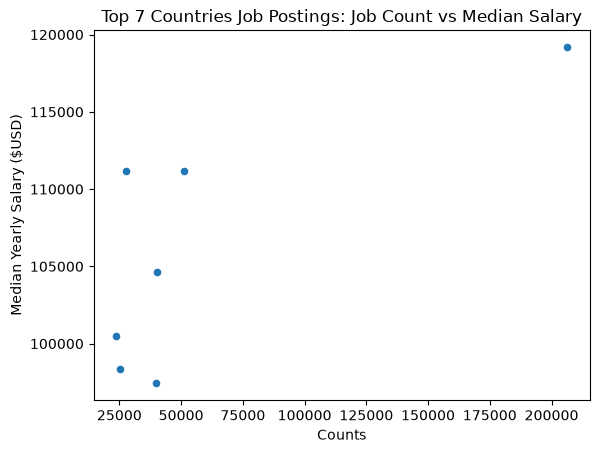

In [11]:
top_countries.plot(kind="scatter", x="job_count", y="median_salary_year_avg")
plt.title("Top 7 Countries Job Postings: Job Count vs Median Salary")
plt.xlabel("Counts")
plt.ylabel("Median Yearly Salary ($USD)")
plt.show()

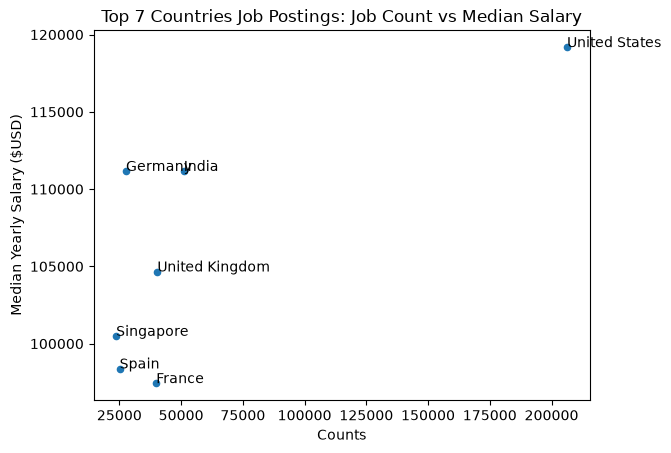

In [12]:
top_countries.plot(kind="scatter", x="job_count", y="median_salary_year_avg")
plt.title("Top 7 Countries Job Postings: Job Count vs Median Salary")
plt.xlabel("Counts")
plt.ylabel("Median Yearly Salary ($USD)")

for i, txt in enumerate(top_countries.index):
    plt.text(top_countries["job_count"].iloc[i], top_countries["median_salary_year_avg"].iloc[i], txt) 

plt.show()

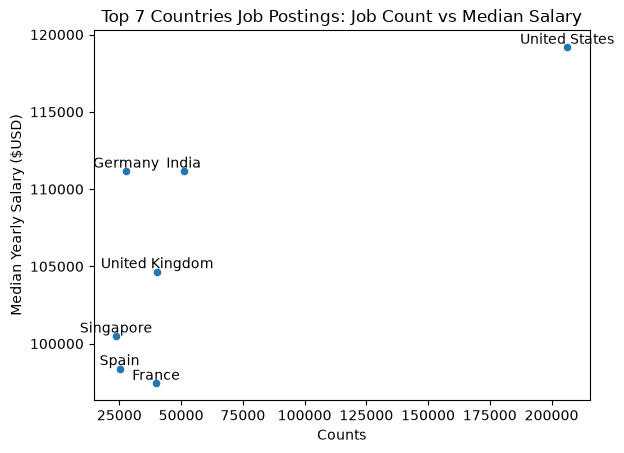

In [13]:
top_countries.plot(kind="scatter", x="job_count", y="median_salary_year_avg")
plt.title("Top 7 Countries Job Postings: Job Count vs Median Salary")
plt.xlabel("Counts")
plt.ylabel("Median Yearly Salary ($USD)")

for i, txt in enumerate(top_countries.index):
    plt.text(top_countries["job_count"].iloc[i], top_countries["median_salary_year_avg"].iloc[i], txt, ha="center", va="bottom") 
# ha stands for Horizontal Alignment and va stands for Vertical Alignment. They control how text is positioned relative to the specified (x, y) coordinates.
plt.show()

### Problem #3 Statement:
Create a scatter plot to visualize the relationship between the average yearly salary and the job count filtering a DataFrame for:
- Data Analyst, Data Scientist, and Data Engineer positions in job_title_short
- United States for the job_country
- 'Full-time' and 'Contractor' for the job_schedule_type
- Remove roles that do not have any yearly salary data.

Combine the job_title_short and job_schedule_type into one column (called job_title_type) in the newly created DataFrame to use as the labels for the plot.

For the plot use a for loop to cycle through the unique values in job_title_type and plot using the plt.scatter() function, specifying the label of job_title_type.

Ensure the legend is appearing.

Label the plot's axis and title appropriately.

In [14]:
df_filter = df[df["job_country"] == "United States"] # to filter for job country as USA
df_filter

,job_title_short,job_title,job_location,job_via,job_schedule_type,job_work_from_home,search_location,job_posted_date,job_no_degree_mention,job_health_insurance,job_country,salary_rate,salary_year_avg,salary_hour_avg,company_name,job_skills,job_type_skills
0,Senior Data Engineer,Senior Clinical Data Engineer / Principal Clin...,"Watertown, CT",via Work Nearby,Full-time,False,"Texas, United States",2023-06-16 13:44:15,False,False,United States,NaN,NaN,NaN,Boehringer Ingelheim,NaN,NaN
3,Data Engineer,LEAD ENGINEER - PRINCIPAL ANALYST - PRINCIPAL ...,"San Antonio, TX",via Diversity.com,Full-time,False,"Texas, United States",2023-07-04 13:01:41,True,False,United States,NaN,NaN,NaN,Southwest Research Institute,"[python, c++, java, matlab, aws, tensorflow, k...","{'cloud': ['aws'], 'libraries': ['tensorflow',..."
5,Data Engineer,GCP Data Engineer,Anywhere,via ZipRecruiter,Contractor and Temp work,True,Georgia,2023-11-07 14:01:59,False,False,United States,NaN,NaN,NaN,smart folks inc,"[python, sql, gcp]","{'cloud': ['gcp'], 'programming': ['python', '..."
6,Senior Data Engineer,Senior Data Engineer - GCP Cloud,"Dearborn, MI",via LinkedIn,Full-time,False,"Florida, United States",2023-03-27 13:18:18,False,False,United States,NaN,NaN,NaN,"Miracle Software Systems, Inc","[sql, python, java, sql server, gcp, bigquery,...","{'cloud': ['gcp', 'bigquery'], 'databases': ['..."
9,Data Scientist,Data Scientist II,Anywhere,via ZipRecruiter,Full-time,True,"New York, United States",2023-04-23 13:02:57,False,False,United States,NaN,NaN,NaN,"Radwell International, LLC","[sql, python, r, mongodb, mongodb, sql server,...","{'analyst_tools': ['excel'], 'cloud': ['azure'..."
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
785673,Data Scientist,Asset Management Data Scientist,"New York, NY",via Trabajo.org,Full-time,False,"New York, United States",2023-10-16 06:01:53,True,False,United States,NaN,NaN,NaN,JPMorgan Chase & Co.,NaN,NaN
785685,Data Analyst,Data Analyst,"Indianapolis, IN",via Trabajo.org,Full-time,False,"Illinois, United States",2023-07-16 06:01:27,True,False,United States,NaN,NaN,NaN,"Aara Technologies, Inc","[sql, excel]","{'analyst_tools': ['excel'], 'programming': ['..."
785692,Data Scientist,Data Scientist- Hybrid Work Location,"Dayton, OH",via Ai-Jobs.net,Full-time,False,"Illinois, United States",2023-04-21 06:02:31,False,True,United States,year,157500.0,NaN,Tenet3,"[python, matlab, r]","{'programming': ['python', 'matlab', 'r']}"
785703,Data Analyst,Data Analyst - CRYPTOGRAPHY - Full-time,Anywhere,via Snagajob,Full-time,True,"Texas, United States",2023-01-28 06:02:55,True,False,United States,NaN,NaN,NaN,Axelon Services Corporation,NaN,NaN


In [15]:
df_filter = df_filter[df_filter["job_title_short"].isin(['Data Analyst', 'Data Scientist', 'Data Engineer'])] # using isin to include only df with DA, DS, DE
df_filter


,job_title_short,job_title,job_location,job_via,job_schedule_type,job_work_from_home,search_location,job_posted_date,job_no_degree_mention,job_health_insurance,job_country,salary_rate,salary_year_avg,salary_hour_avg,company_name,job_skills,job_type_skills
3,Data Engineer,LEAD ENGINEER - PRINCIPAL ANALYST - PRINCIPAL ...,"San Antonio, TX",via Diversity.com,Full-time,False,"Texas, United States",2023-07-04 13:01:41,True,False,United States,NaN,NaN,NaN,Southwest Research Institute,"[python, c++, java, matlab, aws, tensorflow, k...","{'cloud': ['aws'], 'libraries': ['tensorflow',..."
5,Data Engineer,GCP Data Engineer,Anywhere,via ZipRecruiter,Contractor and Temp work,True,Georgia,2023-11-07 14:01:59,False,False,United States,NaN,NaN,NaN,smart folks inc,"[python, sql, gcp]","{'cloud': ['gcp'], 'programming': ['python', '..."
9,Data Scientist,Data Scientist II,Anywhere,via ZipRecruiter,Full-time,True,"New York, United States",2023-04-23 13:02:57,False,False,United States,NaN,NaN,NaN,"Radwell International, LLC","[sql, python, r, mongodb, mongodb, sql server,...","{'analyst_tools': ['excel'], 'cloud': ['azure'..."
11,Data Engineer,Data Engineer,"Colorado Springs, CO (+3 others)",via The Muse,Full-time,False,"Texas, United States",2023-11-03 13:06:51,False,True,United States,NaN,NaN,NaN,Philips,"[python, qlik]","{'analyst_tools': ['qlik'], 'programming': ['p..."
17,Data Scientist,Data Science Team Lead,"Laurel, MD",via APL Careers - Johns Hopkins University App...,Full-time,False,Georgia,2023-06-13 13:25:17,False,True,United States,NaN,NaN,NaN,Johns Hopkins Applied Physics Laboratory,"[go, apl, excel]","{'analyst_tools': ['excel'], 'programming': ['..."
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
785673,Data Scientist,Asset Management Data Scientist,"New York, NY",via Trabajo.org,Full-time,False,"New York, United States",2023-10-16 06:01:53,True,False,United States,NaN,NaN,NaN,JPMorgan Chase & Co.,NaN,NaN
785685,Data Analyst,Data Analyst,"Indianapolis, IN",via Trabajo.org,Full-time,False,"Illinois, United States",2023-07-16 06:01:27,True,False,United States,NaN,NaN,NaN,"Aara Technologies, Inc","[sql, excel]","{'analyst_tools': ['excel'], 'programming': ['..."
785692,Data Scientist,Data Scientist- Hybrid Work Location,"Dayton, OH",via Ai-Jobs.net,Full-time,False,"Illinois, United States",2023-04-21 06:02:31,False,True,United States,year,157500.0,NaN,Tenet3,"[python, matlab, r]","{'programming': ['python', 'matlab', 'r']}"
785703,Data Analyst,Data Analyst - CRYPTOGRAPHY - Full-time,Anywhere,via Snagajob,Full-time,True,"Texas, United States",2023-01-28 06:02:55,True,False,United States,NaN,NaN,NaN,Axelon Services Corporation,NaN,NaN


In [16]:
df_filter = df_filter[df_filter["job_schedule_type"].isin(["Full-time", "Contractor"])] # to icnlude only df with Fulltime and Contractor
df_filter

,job_title_short,job_title,job_location,job_via,job_schedule_type,job_work_from_home,search_location,job_posted_date,job_no_degree_mention,job_health_insurance,job_country,salary_rate,salary_year_avg,salary_hour_avg,company_name,job_skills,job_type_skills
3,Data Engineer,LEAD ENGINEER - PRINCIPAL ANALYST - PRINCIPAL ...,"San Antonio, TX",via Diversity.com,Full-time,False,"Texas, United States",2023-07-04 13:01:41,True,False,United States,NaN,NaN,NaN,Southwest Research Institute,"[python, c++, java, matlab, aws, tensorflow, k...","{'cloud': ['aws'], 'libraries': ['tensorflow',..."
9,Data Scientist,Data Scientist II,Anywhere,via ZipRecruiter,Full-time,True,"New York, United States",2023-04-23 13:02:57,False,False,United States,NaN,NaN,NaN,"Radwell International, LLC","[sql, python, r, mongodb, mongodb, sql server,...","{'analyst_tools': ['excel'], 'cloud': ['azure'..."
11,Data Engineer,Data Engineer,"Colorado Springs, CO (+3 others)",via The Muse,Full-time,False,"Texas, United States",2023-11-03 13:06:51,False,True,United States,NaN,NaN,NaN,Philips,"[python, qlik]","{'analyst_tools': ['qlik'], 'programming': ['p..."
17,Data Scientist,Data Science Team Lead,"Laurel, MD",via APL Careers - Johns Hopkins University App...,Full-time,False,Georgia,2023-06-13 13:25:17,False,True,United States,NaN,NaN,NaN,Johns Hopkins Applied Physics Laboratory,"[go, apl, excel]","{'analyst_tools': ['excel'], 'programming': ['..."
26,Data Engineer,Data Engineer,United States,via LinkedIn,Full-time,False,Georgia,2023-09-15 13:56:18,True,False,United States,NaN,NaN,NaN,Infinite Computer Solutions,NaN,NaN
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
785673,Data Scientist,Asset Management Data Scientist,"New York, NY",via Trabajo.org,Full-time,False,"New York, United States",2023-10-16 06:01:53,True,False,United States,NaN,NaN,NaN,JPMorgan Chase & Co.,NaN,NaN
785685,Data Analyst,Data Analyst,"Indianapolis, IN",via Trabajo.org,Full-time,False,"Illinois, United States",2023-07-16 06:01:27,True,False,United States,NaN,NaN,NaN,"Aara Technologies, Inc","[sql, excel]","{'analyst_tools': ['excel'], 'programming': ['..."
785692,Data Scientist,Data Scientist- Hybrid Work Location,"Dayton, OH",via Ai-Jobs.net,Full-time,False,"Illinois, United States",2023-04-21 06:02:31,False,True,United States,year,157500.0,NaN,Tenet3,"[python, matlab, r]","{'programming': ['python', 'matlab', 'r']}"
785703,Data Analyst,Data Analyst - CRYPTOGRAPHY - Full-time,Anywhere,via Snagajob,Full-time,True,"Texas, United States",2023-01-28 06:02:55,True,False,United States,NaN,NaN,NaN,Axelon Services Corporation,NaN,NaN


In [17]:
df_filter = df_filter.dropna(subset="salary_year_avg") # df_filtered = df.dropna(subset=["column_name"]) to remove rows for column salary_year_avg containing NaN
df_filter
# now finaly the df is fully filtered as requested

,job_title_short,job_title,job_location,job_via,job_schedule_type,job_work_from_home,search_location,job_posted_date,job_no_degree_mention,job_health_insurance,job_country,salary_rate,salary_year_avg,salary_hour_avg,company_name,job_skills,job_type_skills
92,Data Engineer,Remote - Data Engineer - Permanent - W2,Anywhere,via LinkedIn,Full-time,True,"Illinois, United States",2023-02-21 13:29:59,False,True,United States,year,120000.0,NaN,Apex Systems,"[sql, python]","{'programming': ['sql', 'python']}"
100,Data Scientist,"Data Scientist, Risk Data Mining - USDS","Mountain View, CA",via LinkedIn,Full-time,False,"California, United States",2023-07-31 13:01:18,False,True,United States,year,228222.0,NaN,TikTok,"[sql, r, python, express]","{'programming': ['sql', 'r', 'python'], 'webfr..."
109,Data Analyst,Senior Supply Chain Analytics Analyst,Anywhere,via Get.It,Full-time,True,"Illinois, United States",2023-10-12 13:02:19,False,True,United States,year,89000.0,NaN,Get It Recruit - Transportation,"[python, r, alteryx, tableau]","{'analyst_tools': ['alteryx', 'tableau'], 'pro..."
116,Data Scientist,Data Scientist,Anywhere,via LinkedIn,Full-time,True,"Texas, United States",2023-10-04 13:04:23,False,False,United States,year,114000.0,NaN,4 Corner Resources,"[r, python, sql, t-sql, hadoop, spark, tableau]","{'analyst_tools': ['tableau'], 'libraries': ['..."
146,Data Engineer,Data Engineer Graduate (Real Time Communicatio...,"Seattle, WA",via LinkedIn,Full-time,False,"California, United States",2023-10-21 13:06:16,False,True,United States,year,129500.0,NaN,ByteDance,"[golang, scala, python, java, hadoop, spark]","{'libraries': ['hadoop', 'spark'], 'programmin..."
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
785563,Data Scientist,Data Scientist I/II (Model Risk Management & M...,"Pensacola, FL",via Navy Federal Credit Union - Talentify,Full-time,False,"Florida, United States",2023-01-11 06:22:10,False,False,United States,year,136400.0,NaN,Navy Federal Credit Union,"[r, python, matplotlib, ggplot2, spark, word, ...","{'analyst_tools': ['word', 'power bi', 'tablea..."
785624,Data Engineer,Data Analytics Engineer (Hybrid),"Mt Prospect, IL",via Ai-Jobs.net,Full-time,False,"Illinois, United States",2023-08-31 06:02:16,False,True,United States,year,139216.0,NaN,Bosch Group,"[go, python, r, sql, oracle, windows, alteryx,...","{'analyst_tools': ['alteryx', 'power bi', 'tab..."
785641,Data Engineer,Data Engineer,"New York, NY",via Dice,Full-time,False,Georgia,2023-01-04 16:36:07,True,False,United States,year,150000.0,NaN,"Engage Partners, Inc.",NaN,NaN
785648,Data Scientist,Director Data Scientist - Commercial Platforms...,"Pleasant Hill, CA",via Ai-Jobs.net,Full-time,False,"California, United States",2023-04-12 06:02:51,False,True,United States,year,221875.0,NaN,84.51°,"[python, azure, snowflake, spark]","{'cloud': ['azure', 'snowflake'], 'libraries':..."


In [18]:
target_job_titles = ['Data Analyst', 'Data Scientist', 'Data Engineer']

### Cleaner way of solving

In [19]:
# The cleaner way of filtering using bitwise AND &

us_jobs_df = df[
   (df['job_country'] == 'United States') &
   (df['job_schedule_type'].isin(['Full-time', 'Contractor'])) &
   (df['job_title_short'].isin(target_job_titles))
].dropna(subset=['salary_year_avg']).copy()

us_jobs_df
# copy df
# df[(selection) & (selection) & (selection)]

,job_title_short,job_title,job_location,job_via,job_schedule_type,job_work_from_home,search_location,job_posted_date,job_no_degree_mention,job_health_insurance,job_country,salary_rate,salary_year_avg,salary_hour_avg,company_name,job_skills,job_type_skills
92,Data Engineer,Remote - Data Engineer - Permanent - W2,Anywhere,via LinkedIn,Full-time,True,"Illinois, United States",2023-02-21 13:29:59,False,True,United States,year,120000.0,NaN,Apex Systems,"[sql, python]","{'programming': ['sql', 'python']}"
100,Data Scientist,"Data Scientist, Risk Data Mining - USDS","Mountain View, CA",via LinkedIn,Full-time,False,"California, United States",2023-07-31 13:01:18,False,True,United States,year,228222.0,NaN,TikTok,"[sql, r, python, express]","{'programming': ['sql', 'r', 'python'], 'webfr..."
109,Data Analyst,Senior Supply Chain Analytics Analyst,Anywhere,via Get.It,Full-time,True,"Illinois, United States",2023-10-12 13:02:19,False,True,United States,year,89000.0,NaN,Get It Recruit - Transportation,"[python, r, alteryx, tableau]","{'analyst_tools': ['alteryx', 'tableau'], 'pro..."
116,Data Scientist,Data Scientist,Anywhere,via LinkedIn,Full-time,True,"Texas, United States",2023-10-04 13:04:23,False,False,United States,year,114000.0,NaN,4 Corner Resources,"[r, python, sql, t-sql, hadoop, spark, tableau]","{'analyst_tools': ['tableau'], 'libraries': ['..."
146,Data Engineer,Data Engineer Graduate (Real Time Communicatio...,"Seattle, WA",via LinkedIn,Full-time,False,"California, United States",2023-10-21 13:06:16,False,True,United States,year,129500.0,NaN,ByteDance,"[golang, scala, python, java, hadoop, spark]","{'libraries': ['hadoop', 'spark'], 'programmin..."
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
785563,Data Scientist,Data Scientist I/II (Model Risk Management & M...,"Pensacola, FL",via Navy Federal Credit Union - Talentify,Full-time,False,"Florida, United States",2023-01-11 06:22:10,False,False,United States,year,136400.0,NaN,Navy Federal Credit Union,"[r, python, matplotlib, ggplot2, spark, word, ...","{'analyst_tools': ['word', 'power bi', 'tablea..."
785624,Data Engineer,Data Analytics Engineer (Hybrid),"Mt Prospect, IL",via Ai-Jobs.net,Full-time,False,"Illinois, United States",2023-08-31 06:02:16,False,True,United States,year,139216.0,NaN,Bosch Group,"[go, python, r, sql, oracle, windows, alteryx,...","{'analyst_tools': ['alteryx', 'power bi', 'tab..."
785641,Data Engineer,Data Engineer,"New York, NY",via Dice,Full-time,False,Georgia,2023-01-04 16:36:07,True,False,United States,year,150000.0,NaN,"Engage Partners, Inc.",NaN,NaN
785648,Data Scientist,Director Data Scientist - Commercial Platforms...,"Pleasant Hill, CA",via Ai-Jobs.net,Full-time,False,"California, United States",2023-04-12 06:02:51,False,True,United States,year,221875.0,NaN,84.51°,"[python, azure, snowflake, spark]","{'cloud': ['azure', 'snowflake'], 'libraries':..."


In [20]:
stats = us_jobs_df.groupby(['job_schedule_type', 'job_title_short']).agg( 
   mean_salary_year_avg=('salary_year_avg', 'mean'),
   job_count=('job_title_short', 'count')
).dropna()

stats

mean_salary_year_avg  job_count
job_schedule_type job_title_short                                 
Contractor        Data Analyst             87027.197142        111
                  Data Engineer           117772.326225         74
                  Data Scientist          118568.074155         61
Full-time         Data Analyst             95072.545202       4097
                  Data Engineer           133804.432239       2759
                  Data Scientist          140848.379828       4325

In [21]:
stats.reset_index(inplace=True) # no need to assign dataframe as we use inplace

stats

,job_schedule_type,job_title_short,mean_salary_year_avg,job_count
0,Contractor,Data Analyst,87027.197142,111
1,Contractor,Data Engineer,117772.326225,74
2,Contractor,Data Scientist,118568.074155,61
3,Full-time,Data Analyst,95072.545202,4097
4,Full-time,Data Engineer,133804.432239,2759
5,Full-time,Data Scientist,140848.379828,4325


In [22]:
stats['job_title_type'] = stats['job_title_short'] + ' - ' + stats['job_schedule_type'] # Combine the job_title_short and job_schedule_type into one column (called job_title_type)

stats

,job_schedule_type,job_title_short,mean_salary_year_avg,job_count,job_title_type
0,Contractor,Data Analyst,87027.197142,111,Data Analyst - Contractor
1,Contractor,Data Engineer,117772.326225,74,Data Engineer - Contractor
2,Contractor,Data Scientist,118568.074155,61,Data Scientist - Contractor
3,Full-time,Data Analyst,95072.545202,4097,Data Analyst - Full-time
4,Full-time,Data Engineer,133804.432239,2759,Data Engineer - Full-time
5,Full-time,Data Scientist,140848.379828,4325,Data Scientist - Full-time


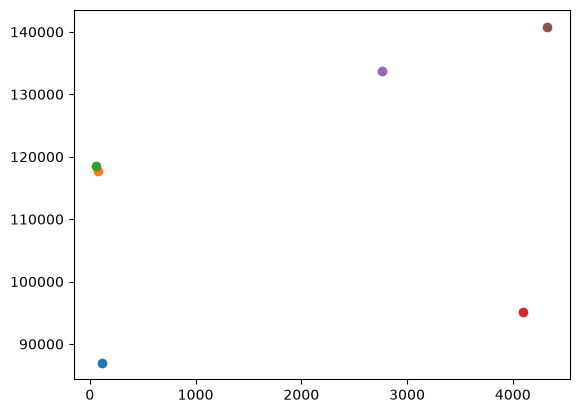

In [ ]:
for job_title_type in stats['job_title_type'].unique():
   subset = stats[stats['job_title_type'] == job_title_type]
   plt.scatter(subset['job_count'], subset['mean_salary_year_avg'], label=job_title_type)

# 1. stats['job_title_type'].unique()
# - stats['job_title_type']: Selects the combined column containing combined title and schedule strings (e.g., 'Data Analyst - Contractor' or 'Data Scientist - Full-time').   
# - .unique(): Extracts an array of only the distinct category names from that column, ignoring duplicate entries.

# 2. for job_title_type in ...:
# - Sets up a for loop to iterate through each distinct job title category string one by one.

# 3. subset = stats[stats['job_title_type'] == job_title_type]
# - Performs a boolean filter on the stats DataFrame.   
# - Creates a temporary filtered DataFrame called subset containing only the row(s) that match the current category in the loop.

# 5. subset['job_count'] (1st argument in plt.scatter)
# - Supplies the numerical value for the X-axis coordinate (the job count for that specific category).

# 6. subset['mean_salary_year_avg'] (2nd argument in plt.scatter)
# - Supplies the numerical value for the Y-axis coordinate (the average salary for that specific category).


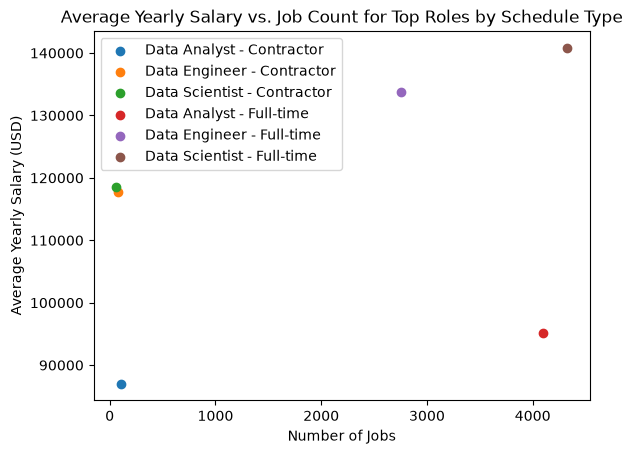

In [24]:
for job_title_type in stats['job_title_type'].unique():
   subset = stats[stats['job_title_type'] == job_title_type]
   plt.scatter(subset['job_count'], subset['mean_salary_year_avg'], label=job_title_type)

plt.xlabel('Number of Jobs')
plt.ylabel('Average Yearly Salary (USD)')
plt.title('Average Yearly Salary vs. Job Count for Top Roles by Schedule Type')
plt.legend()
plt.show()